# Praktikum 3 - DBSCAN (Density-Based Spatial Clustering of Applications with Noise)

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 04:** Klasterisasi

### Tujuan Praktikum:
1. Membangun dataset sintetis 3 klaster menggunakan `make_blobs` dan melakukan standardisasi.
2. Menerapkan algoritma DBSCAN (`eps=0.3`, `min_samples=10`).
3. Mengevaluasi kualitas klasterisasi menggunakan metrik: Homogeneity, Completeness, V-measure, Adjusted Rand Index (ARI), Adjusted Mutual Information (AMI), dan Silhouette Score.
4. Memvisualisasikan *core samples*, *non-core samples*, dan *noise/outliers*.

## Langkah 1 - Pembuatan Dataset Sintetis

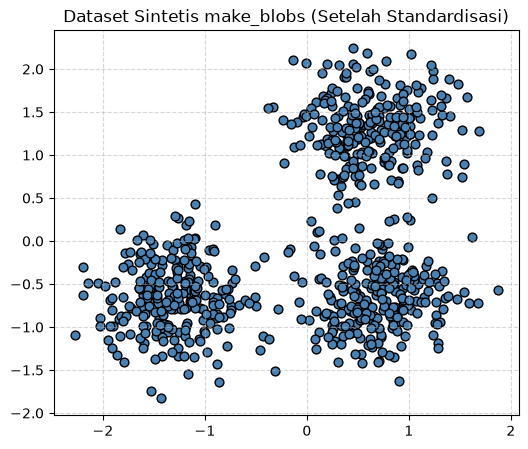

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn import metrics

centers = [[1, 1], [-1, -1], [1, -1]]
X, labels_true = make_blobs(n_samples=750, centers=centers, cluster_std=0.4, random_state=0)
X = StandardScaler().fit_transform(X)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], s=40, c='steelblue', edgecolors='k')
plt.title('Dataset Sintetis make_blobs (Setelah Standardisasi)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Langkah 2 - Menerapkan Model DBSCAN

In [2]:
db = DBSCAN(eps=0.3, min_samples=10).fit(X)
labels = db.labels_

# Menghitung jumlah cluster (mengabaikan noise -1)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f'Estimasi Jumlah Klaster: {n_clusters_}')
print(f'Estimasi Titik Noise (Outlier): {n_noise_}')

Estimasi Jumlah Klaster: 3
Estimasi Titik Noise (Outlier): 18


## Langkah 3 - Evaluasi Kualitas Klasterisasi

In [3]:
print(f'Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}')
print(f'Completeness: {metrics.completeness_score(labels_true, labels):.3f}')
print(f'V-measure: {metrics.v_measure_score(labels_true, labels):.3f}')
print(f'Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}')
print(f'Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}')
print(f'Silhouette Coefficient: {metrics.silhouette_score(X, labels):.3f}')

Homogeneity: 0.953
Completeness: 0.883
V-measure: 0.917
Adjusted Rand Index: 0.952
Adjusted Mutual Information: 0.916
Silhouette Coefficient: 0.626


## Langkah 4 - Visualisasi Hasil Klasterisasi DBSCAN
- **Titik Besar Berwarna**: Core sample
- **Titik Kecil Berwarna**: Non-core boundary sample
- **Titik Hitam**: Noise / Outlier

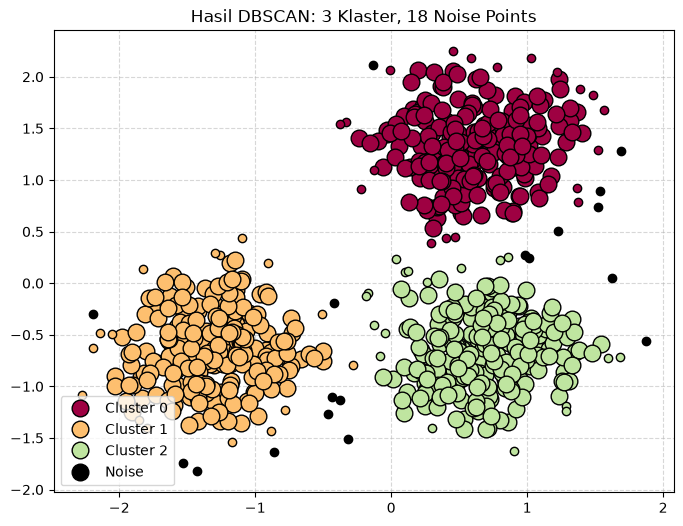

In [4]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

plt.figure(figsize=(8, 6))
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Titik hitam untuk noise

    class_member_mask = (labels == k)

    # Plot Core Samples (Titik Besar)
    xy = X[class_member_mask & core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=12, label=f'Cluster {k}' if k != -1 else 'Noise')

    # Plot Non-core Samples (Titik Kecil)
    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)

plt.title(f'Hasil DBSCAN: {n_clusters_} Klaster, {n_noise_} Noise Points')
plt.legend(loc='lower left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()